# Rock, Paper, Scissors: Image Classification

**ENGR 418 · Team 24**

We wanted to see how well a computer could recognize rock, paper, and scissors from pictures of hands, and what changes when we adjust the way the images are represented or the way a model is trained.

We'll work through the images, look at PCA, establish a basic classifier, and compare it with a small neural network. We are keeping the original `principal-component-analysis-visualization.ipynb` in this repository as a reference; **this is the notebook where we run and document our own experiments**.

The idea is to make comparisons we can actually explain, rather than trying to get the highest possible accuracy by changing everything at once.

## 1. Our images

Our repository has an `rps` folder for developing the models and a separate `rps-test-set` folder. We will split `rps` into training and validation data. The test images stay aside until the end.

For now, we resize each image, convert it to grayscale, and turn it into a row of pixel values between 0 and 1. If we decide to remove the green background or change the image size, we'll make that change **here**, so every model uses exactly the same processed images.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, log_loss,
    mean_squared_error
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

SEED = 42
CLASSES = ["rock", "paper", "scissors"]
IMAGE_SIZE = (48, 48)  # width, height
PCA_COUNTS = [5, 10, 25, 50, 100, 200]
ITERATION_LIMITS = [5, 10, 25, 50, 100, 200, 500]

# Codespaces notebooks may be opened from the repository root or notebooks/.
if "RPS_PROJECT_ROOT" in os.environ:
    ROOT = Path(os.environ["RPS_PROJECT_ROOT"]).expanduser().resolve()
else:
    ROOT = next(
        (folder for folder in [Path.cwd(), *Path.cwd().parents]
         if (folder / "Dataset" / "rps").is_dir()),
        Path.cwd()
    )
DATA_DIR = ROOT / "Dataset"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True, parents=True)

print("Project folder:", ROOT)
print("Image dimensions:", IMAGE_SIZE)

Project folder: /workspaces/ENGR-418-Machine-Learning-Project
Image dimensions: (48, 48)


In [2]:
def list_images(folder):
    items = []
    for class_id, name in enumerate(CLASSES):
        class_folder = folder / name
        if not class_folder.is_dir():
            raise FileNotFoundError(f"Can't find {class_folder}")
        for image_path in sorted(class_folder.rglob("*")):
            if image_path.is_file() and image_path.suffix.lower() in {".png", ".jpg", ".jpeg"}:
                items.append((image_path, class_id))
    return items


def prepare_image(path):
    with Image.open(path) as image:
        gray = image.convert("L")
        resized = ImageOps.pad(
            gray, IMAGE_SIZE, method=Image.Resampling.LANCZOS, color=0
        )
        return np.asarray(resized, dtype=np.float32) / 255.0


def load_images(folder):
    files = list_images(folder)
    if not files:
        raise ValueError(f"No image files found in {folder}")
    images = np.stack([prepare_image(path) for path, _ in files])
    labels = np.array([label for _, label in files], dtype=int)
    paths = np.array([str(path.relative_to(ROOT)) for path, _ in files])
    return images, labels, paths


images_pool, y_pool, pool_paths = load_images(DATA_DIR / "rps")
images_test, y_test, test_paths = load_images(DATA_DIR / "rps-test-set")

counts = pd.DataFrame({
    "gesture": CLASSES,
    "development_images": [int(np.sum(y_pool == i)) for i in range(3)],
    "held_out_test_images": [int(np.sum(y_test == i)) for i in range(3)],
})
display(counts)
print("Total images:", len(images_pool) + len(images_test))
assert set(y_pool) == set(y_test) == {0, 1, 2}

,gesture,development_images,held_out_test_images
0,rock,840,124
1,paper,840,124
2,scissors,840,124


Total images: 2892


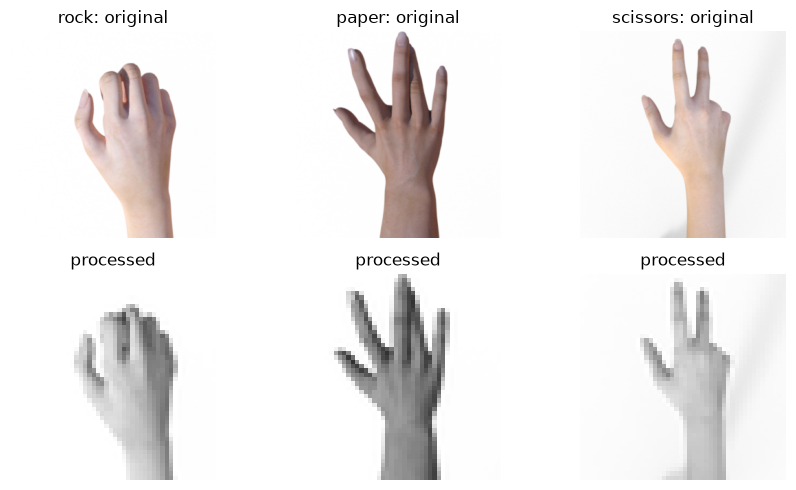

In [3]:
# Look at one example per gesture before doing anything else.
fig, axes = plt.subplots(2, 3, figsize=(9, 5))
for label_id, gesture in enumerate(CLASSES):
    idx = int(np.flatnonzero(y_pool == label_id)[0])
    with Image.open(ROOT / pool_paths[idx]) as original:
        axes[0, label_id].imshow(original)
    axes[0, label_id].set_title(f"{gesture}: original")
    axes[1, label_id].imshow(images_pool[idx], cmap="gray", vmin=0, vmax=1)
    axes[1, label_id].set_title("processed")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "image_preprocessing_examples.png", dpi=160)
plt.show()

### A quick dataset check

The folder structure gives us labels, but it doesn't guarantee that the training and test collections are independent. We check for **exact duplicate files** below. That won't catch near-duplicates such as adjacent frames or slightly edited copies, so we'll also need to consider that limitation when discussing the results.

In [4]:
def file_hashes(paths):
    hashes = set()
    for relative_path in paths:
        with open(ROOT / relative_path, "rb") as file:
            digest = hashlib.sha256(file.read()).hexdigest()
        hashes.add(digest)
    return hashes

matching_files = file_hashes(pool_paths) & file_hashes(test_paths)
print("Exact duplicate file hashes shared by the two folders:", len(matching_files))
if matching_files:
    print("Check the dataset before treating the second folder as an independent test set.")

Exact duplicate file hashes shared by the two folders: 0


## 2. Split the data and set up the features

The main image collection is split into training (80%) and validation (20%) sets, with the class proportions preserved. The random seed makes the split repeatable. We save the filenames and their assignments so the same partitions can be reused throughout the project.

A grayscale image of size 48 × 48 becomes a vector of 2,304 pixel values. This gives us a fairly large number of inputs for a relatively small image dataset.

In [5]:
indices = np.arange(len(y_pool))
train_ids, val_ids = train_test_split(
    indices, test_size=0.20, stratify=y_pool, random_state=SEED
)

X_train = images_pool[train_ids].reshape(len(train_ids), -1)
X_val = images_pool[val_ids].reshape(len(val_ids), -1)
X_test = images_test.reshape(len(images_test), -1)
y_train = y_pool[train_ids]
y_val = y_pool[val_ids]

split_table = pd.DataFrame({
    "file": np.concatenate([pool_paths[train_ids], pool_paths[val_ids], test_paths]),
    "gesture": [CLASSES[int(i)] for i in np.concatenate([y_train, y_val, y_test])],
    "split": (["train"] * len(train_ids) + ["validation"] * len(val_ids) +
              ["test"] * len(y_test)),
})
split_table.to_csv(RESULTS_DIR / "data_split.csv", index=False)
display(split_table.groupby(["split", "gesture"]).size().unstack(fill_value=0))
print("Pixel values per image:", X_train.shape[1])

gesture,paper,rock,scissors
split,,,
test,124,124,124
train,672,672,672
validation,168,168,168


Pixel values per image: 2304


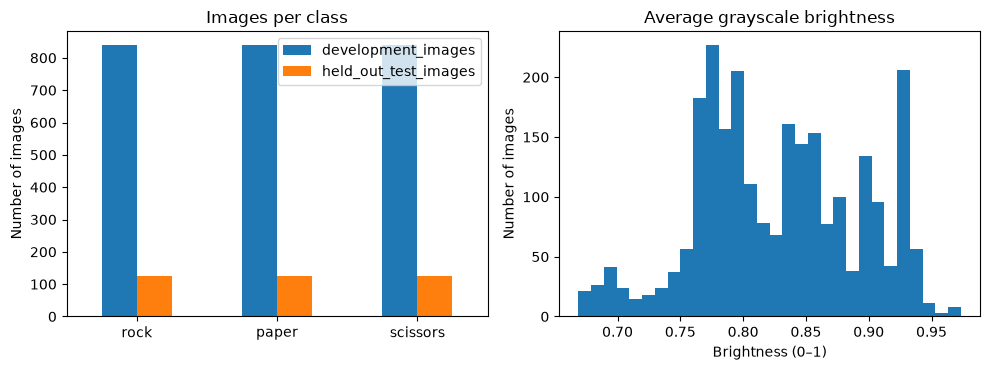

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
counts.set_index("gesture")[["development_images", "held_out_test_images"]].plot.bar(ax=axes[0])
axes[0].set_title("Images per class")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of images")
axes[0].tick_params(axis="x", rotation=0)

brightness = images_pool.mean(axis=(1, 2))
axes[1].hist(brightness, bins=30)
axes[1].set_title("Average grayscale brightness")
axes[1].set_xlabel("Brightness (0–1)")
axes[1].set_ylabel("Number of images")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "dataset_summary.png", dpi=160)
plt.show()

## 3. What does PCA keep?

A lot of pixel values are related to one another. PCA replaces the original features with a smaller set of components that capture directions of variation in the training images. Those directions are not necessarily the same as the features that distinguish rock, paper, and scissors.

We scale the features and fit PCA **using training images only**. Then we apply those fitted transformations to validation and test images. This avoids using information from unseen images while building the features.

In [7]:
pixel_scaler = StandardScaler()
X_train_scaled = pixel_scaler.fit_transform(X_train)
X_val_scaled = pixel_scaler.transform(X_val)
X_test_scaled = pixel_scaler.transform(X_test)

max_components = min(max(PCA_COUNTS), X_train_scaled.shape[0] - 1,
                     X_train_scaled.shape[1])
component_counts = [k for k in PCA_COUNTS if k <= max_components]
if not component_counts:
    raise ValueError("Not enough data for the requested PCA component counts")

pca = PCA(n_components=max_components, svd_solver="randomized", random_state=SEED)
start = time.perf_counter()
raw_pca_train = pca.fit_transform(X_train_scaled)
raw_pca_val = pca.transform(X_val_scaled)
raw_pca_test = pca.transform(X_test_scaled)
pca_seconds = time.perf_counter() - start

# Keep the PCA scores on a similar numerical scale for both classifiers.
component_scaler = StandardScaler()
Z_train = component_scaler.fit_transform(raw_pca_train)
Z_val = component_scaler.transform(raw_pca_val)
Z_test = component_scaler.transform(raw_pca_test)

print(f"PCA fit and transform time: {pca_seconds:.2f} seconds")
print(f"Feature counts to compare: {component_counts}")
print(f"Variance retained by {max_components} components: "
      f"{pca.explained_variance_ratio_.sum():.1%}")

PCA fit and transform time: 1.51 seconds
Feature counts to compare: [5, 10, 25, 50, 100, 200]
Variance retained by 200 components: 98.4%


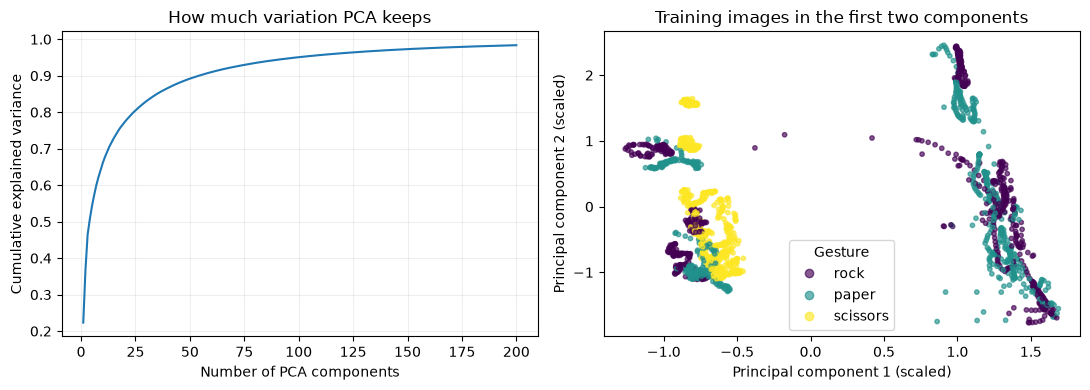

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
variance = np.cumsum(pca.explained_variance_ratio_)
axes[0].plot(np.arange(1, len(variance) + 1), variance)
axes[0].set_xlabel("Number of PCA components")
axes[0].set_ylabel("Cumulative explained variance")
axes[0].set_title("How much variation PCA keeps")
axes[0].grid(alpha=0.2)

scatter = axes[1].scatter(
    Z_train[:, 0], Z_train[:, 1], c=y_train, s=10, alpha=0.65
)
axes[1].set_xlabel("Principal component 1 (scaled)")
axes[1].set_ylabel("Principal component 2 (scaled)")
axes[1].set_title("Training images in the first two components")
legend_handles, _ = scatter.legend_elements()
axes[1].legend(legend_handles, CLASSES, title="Gesture")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "pca_variance_and_projection.png", dpi=160)
plt.show()

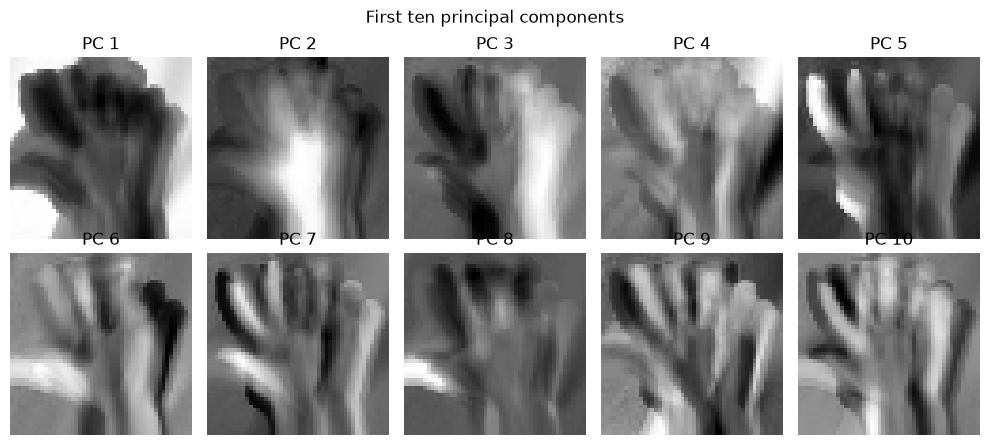

In [9]:
# Reshape the first few PCA directions to see the pixel patterns they describe.
show_count = min(10, len(pca.components_))
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    if i < show_count:
        component_image = pca.components_[i].reshape(IMAGE_SIZE[1], IMAGE_SIZE[0])
        ax.imshow(component_image, cmap="gray")
        ax.set_title(f"PC {i + 1}")
    ax.axis("off")
plt.suptitle("First ten principal components")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "pca_component_images.png", dpi=160)
plt.show()

## 4. Why not ordinary linear regression?

We first tried linear regression as a comparison with what we've learned in class. It can predict numbers, but our labels (`0`, `1`, `2`) are categories, not quantities. A prediction of 1.4 doesn't mean “partly paper.” Rounding the output can give a class label, but that doesn't make the model a proper probabilistic classifier.

This is a short illustration, not an attempt to prove that linear regression always has lower classification accuracy.

Linear regression validation MSE: 0.1377
Accuracy after rounding: 0.869
First ten numerical predictions: [ 1.86  0.66  1.04  1.91  1.08  0.04 -0.18 -0.14  0.17  2.51]


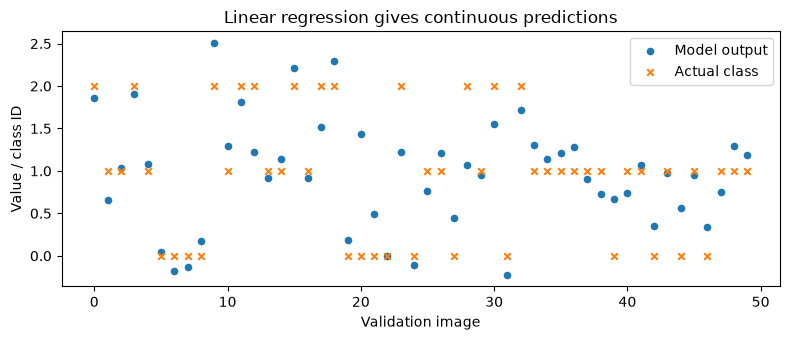

In [10]:
demo_k = min(50, max_components)
linear_regression = LinearRegression()
linear_regression.fit(Z_train[:, :demo_k], y_train)
continuous = linear_regression.predict(Z_val[:, :demo_k])
rounded = np.clip(np.rint(continuous), 0, 2).astype(int)

print("Linear regression validation MSE:", round(mean_squared_error(y_val, continuous), 4))
print("Accuracy after rounding:", round(accuracy_score(y_val, rounded), 4))
print("First ten numerical predictions:", np.round(continuous[:10], 2))

fig, ax = plt.subplots(figsize=(8, 3.5))
example_count = min(50, len(y_val))
ax.scatter(range(example_count), continuous[:example_count], label="Model output", s=20)
ax.scatter(range(example_count), y_val[:example_count], marker="x", label="Actual class", s=22)
ax.set_xlabel("Validation image")
ax.set_ylabel("Value / class ID")
ax.set_title("Linear regression gives continuous predictions")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "linear_regression_example.png", dpi=160)
plt.show()

## 5. Start with logistic regression

For three classes, logistic regression learns a separate score for each gesture. Softmax turns those scores into class probabilities, and we use the class with the highest probability as the prediction.

For image $x$ and class $c$:

$$z_c = w_c^T x + b_c, \qquad p_c = \frac{e^{z_c}}{\sum_j e^{z_j}}$$

The cross-entropy loss penalizes predictions that give low probability to the correct class:

$$L = -\frac{1}{N}\sum_{i=1}^{N}\log p_{y_i}(x_i)$$

We use the scaled pixels for the baseline. After that, we'll change only the input representation to PCA features and compare the results.

In [11]:
def summarize_classifier(model, train_features, val_features, label, training_seconds):
    train_prediction = model.predict(train_features)
    val_prediction = model.predict(val_features)
    val_probability = model.predict_proba(val_features)
    return {
        "model": label,
        "features": train_features.shape[1],
        "training_accuracy": accuracy_score(y_train, train_prediction),
        "validation_accuracy": accuracy_score(y_val, val_prediction),
        "validation_macro_f1": f1_score(y_val, val_prediction, average="macro"),
        "validation_log_loss": log_loss(y_val, val_probability, labels=model.classes_),
        "training_seconds": training_seconds,
    }


def train_logistic(train_features, val_features, label, max_iter=1000):
    model = LogisticRegression(solver="lbfgs", C=1.0, max_iter=max_iter, random_state=SEED)
    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(train_features, y_train)
    elapsed = time.perf_counter() - start
    if any(issubclass(w.category, ConvergenceWarning) for w in caught):
        print(f"{label}: training reached its iteration limit")
    return model, summarize_classifier(model, train_features, val_features, label, elapsed)


raw_model, raw_result = train_logistic(
    X_train_scaled, X_val_scaled, "Logistic regression (pixels)"
)
display(pd.DataFrame([raw_result]).round(4))

,model,features,training_accuracy,validation_accuracy,validation_macro_f1,validation_log_loss,training_seconds
0,Logistic regression (pixels),2304,1.0,1.0,1.0,0.0009,0.659


## 6. Does reducing the number of pixels help?

We'll train the same logistic regression model using different numbers of PCA components. The plot compares training accuracy with validation accuracy, rather than assuming that more features are always better. We will choose a PCA setting from the **validation** results, not from the test data.

In [12]:
pca_models = {}
logistic_rows = [raw_result]
for k in component_counts:
    model, row = train_logistic(
        Z_train[:, :k], Z_val[:, :k], f"Logistic regression (PCA {k})"
    )
    pca_models[k] = model
    logistic_rows.append(row)
    print(f"{k:>3} components: validation accuracy {row['validation_accuracy']:.3f}, "
          f"training time {row['training_seconds']:.2f}s")

logistic_results = pd.DataFrame(logistic_rows)
logistic_results.to_csv(RESULTS_DIR / "logistic_regression_comparison.csv", index=False)
display(logistic_results.round(4))

  5 components: validation accuracy 0.659, training time 0.07s
 10 components: validation accuracy 0.708, training time 0.01s
 25 components: validation accuracy 0.889, training time 0.02s
 50 components: validation accuracy 0.986, training time 0.02s
100 components: validation accuracy 1.000, training time 0.06s
200 components: validation accuracy 1.000, training time 0.06s


,model,features,training_accuracy,validation_accuracy,validation_macro_f1,validation_log_loss,training_seconds
0,Logistic regression (pixels),2304,1.0000,1.0000,1.0000,0.0009,0.6590
1,Logistic regression (PCA 5),5,0.6672,0.6587,0.6461,0.7961,0.0674
2,Logistic regression (PCA 10),10,0.7555,0.7083,0.7060,0.6438,0.0143
3,Logistic regression (PCA 25),25,0.9033,0.8889,0.8883,0.3044,0.0244
4,Logistic regression (PCA 50),50,0.9901,0.9861,0.9861,0.0630,0.0173
5,Logistic regression (PCA 100),100,1.0000,1.0000,1.0000,0.0108,0.0559
6,Logistic regression (PCA 200),200,1.0000,1.0000,1.0000,0.0043,0.0574


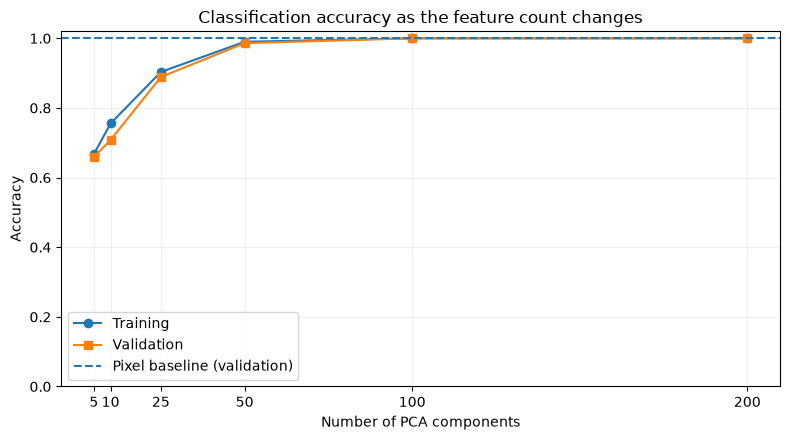

PCA setting selected using validation only: 100 components


In [13]:
pca_rows = logistic_results.iloc[1:].sort_values("features")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pca_rows["features"], pca_rows["training_accuracy"], "o-", label="Training")
ax.plot(pca_rows["features"], pca_rows["validation_accuracy"], "s-", label="Validation")
ax.axhline(raw_result["validation_accuracy"], linestyle="--",
           label="Pixel baseline (validation)")
ax.set_xlabel("Number of PCA components")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.02)
ax.set_xticks(component_counts)
ax.set_title("Classification accuracy as the feature count changes")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "accuracy_vs_pca_components.png", dpi=160)
plt.show()

# Take the smallest representation within 0.5 percentage points of the top validation accuracy.
best_pca_accuracy = pca_rows["validation_accuracy"].max()
eligible = pca_rows[pca_rows["validation_accuracy"] >= best_pca_accuracy - 0.005]
best_k = int(eligible["features"].min())
chosen_pca_model = pca_models[best_k]
print(f"PCA setting selected using validation only: {best_k} components")

## 7. How does the iteration limit affect the loss?

We use 50 PCA components (or the largest available number if there are fewer than 50) and fit the classifier again with different iteration limits. Each point is the final loss from a separate training run. It is **not** a step-by-step loss curve from one run.

,iteration_limit,actual_iterations,training_loss,validation_loss
0,5,5,0.1210,0.1334
1,10,10,0.0542,0.0684
2,25,25,0.0459,0.0634
3,50,29,0.0461,0.0630
4,100,29,0.0461,0.0630
5,200,29,0.0461,0.0630
6,500,29,0.0461,0.0630


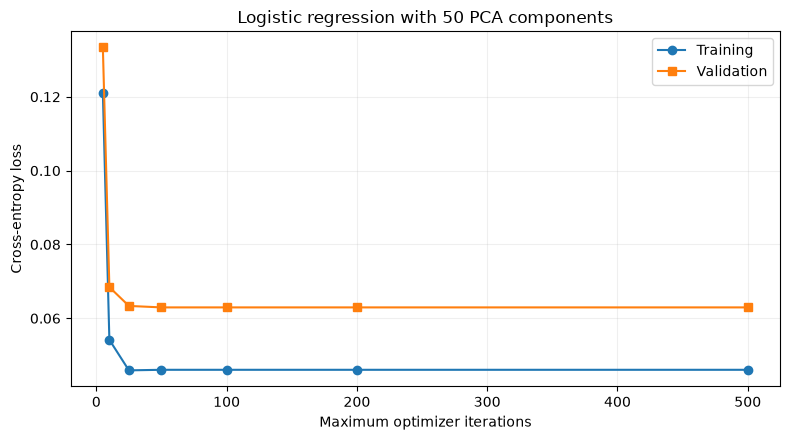

In [14]:
iteration_k = min(50, max_components)
iteration_rows = []
for limit in ITERATION_LIMITS:
    model = LogisticRegression(solver="lbfgs", C=1.0, max_iter=limit, random_state=SEED)
    with warnings.catch_warnings():
        # Small limits are intentional here.
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(Z_train[:, :iteration_k], y_train)
    iteration_rows.append({
        "iteration_limit": limit,
        "actual_iterations": int(model.n_iter_.max()),
        "training_loss": log_loss(
            y_train, model.predict_proba(Z_train[:, :iteration_k]), labels=model.classes_
        ),
        "validation_loss": log_loss(
            y_val, model.predict_proba(Z_val[:, :iteration_k]), labels=model.classes_
        ),
    })

iteration_results = pd.DataFrame(iteration_rows)
iteration_results.to_csv(RESULTS_DIR / "iteration_comparison.csv", index=False)
display(iteration_results.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(iteration_results["iteration_limit"], iteration_results["training_loss"],
        "o-", label="Training")
ax.plot(iteration_results["iteration_limit"], iteration_results["validation_loss"],
        "s-", label="Validation")
ax.set_xlabel("Maximum optimizer iterations")
ax.set_ylabel("Cross-entropy loss")
ax.set_title(f"Logistic regression with {iteration_k} PCA components")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "logistic_regression_iterations.png", dpi=160)
plt.show()

## 8. Try a small neural network

Logistic regression has a linear decision boundary in the feature space. We also want to see whether a small feedforward neural network can learn a relationship that logistic regression misses.

To keep the comparison manageable, we'll use **50 PCA features** (or fewer if necessary), then test a few changes to the learning rate, batch size, and hidden layer size. The configurations below are experiments, not settings we already know will be better.

In [15]:
network_k = min(50, max_components)
network_train = Z_train[:, :network_k]
network_val = Z_val[:, :network_k]
network_test = Z_test[:, :network_k]

# Change one setting at a time relative to the reference network.
network_settings = [
    {"name": "MLP reference", "learning_rate_init": 0.001, "batch_size": 32,
     "hidden_layer_sizes": (64,)},
    {"name": "MLP learning rate 0.0001", "learning_rate_init": 0.0001,
     "batch_size": 32, "hidden_layer_sizes": (64,)},
    {"name": "MLP learning rate 0.01", "learning_rate_init": 0.01,
     "batch_size": 32, "hidden_layer_sizes": (64,)},
    {"name": "MLP batch size 16", "learning_rate_init": 0.001,
     "batch_size": 16, "hidden_layer_sizes": (64,)},
    {"name": "MLP batch size 64", "learning_rate_init": 0.001,
     "batch_size": 64, "hidden_layer_sizes": (64,)},
    {"name": "MLP 32 hidden units", "learning_rate_init": 0.001,
     "batch_size": 32, "hidden_layer_sizes": (32,)},
    {"name": "MLP 128 hidden units", "learning_rate_init": 0.001,
     "batch_size": 32, "hidden_layer_sizes": (128,)},
]

network_models = {}
network_rows = []
for settings in network_settings:
    name = settings["name"]
    params = {k: v for k, v in settings.items() if k != "name"}
    model = MLPClassifier(
        **params, max_iter=200, random_state=SEED, solver="adam"
    )
    start = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(network_train, y_train)
    elapsed = time.perf_counter() - start
    network_models[name] = model
    network_rows.append(summarize_classifier(
        model, network_train, network_val, name, elapsed
    ))
    print(f"{name}: validation accuracy {network_rows[-1]['validation_accuracy']:.3f}")

network_results = pd.DataFrame(network_rows)
network_results.to_csv(RESULTS_DIR / "neural_network_comparison.csv", index=False)
display(network_results.round(4))

MLP reference: validation accuracy 1.000
MLP learning rate 0.0001: validation accuracy 1.000
MLP learning rate 0.01: validation accuracy 1.000
MLP batch size 16: validation accuracy 1.000
MLP batch size 64: validation accuracy 1.000
MLP 32 hidden units: validation accuracy 1.000
MLP 128 hidden units: validation accuracy 1.000


,model,features,training_accuracy,validation_accuracy,validation_macro_f1,validation_log_loss,training_seconds
0,MLP reference,50,1.0,1.0,1.0,0.0010,1.0499
1,MLP learning rate 0.0001,50,1.0,1.0,1.0,0.0025,3.7837
2,MLP learning rate 0.01,50,1.0,1.0,1.0,0.0001,0.5765
3,MLP batch size 16,50,1.0,1.0,1.0,0.0005,1.5919
4,MLP batch size 64,50,1.0,1.0,1.0,0.0017,0.8167
5,MLP 32 hidden units,50,1.0,1.0,1.0,0.0012,1.2358
6,MLP 128 hidden units,50,1.0,1.0,1.0,0.0010,1.2486


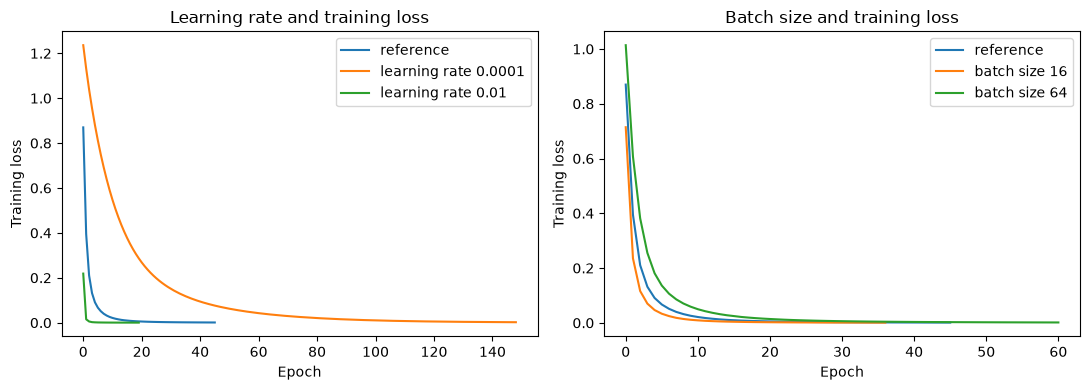

Neural network selected from validation results: MLP learning rate 0.01


In [16]:
# The loss curves below come from each network's own training process.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in ["MLP reference", "MLP learning rate 0.0001", "MLP learning rate 0.01"]:
    axes[0].plot(network_models[name].loss_curve_, label=name.replace("MLP ", ""))
axes[0].set_title("Learning rate and training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training loss")
axes[0].legend()

for name in ["MLP reference", "MLP batch size 16", "MLP batch size 64"]:
    axes[1].plot(network_models[name].loss_curve_, label=name.replace("MLP ", ""))
axes[1].set_title("Batch size and training loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Training loss")
axes[1].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "neural_network_loss_curves.png", dpi=160)
plt.show()

# Choose using validation results only. In a tie, keep the first simpler setting listed.
chosen_network_name = network_results.sort_values(
    ["validation_accuracy", "validation_log_loss"], ascending=[False, True]
).iloc[0]["model"]
chosen_network = network_models[chosen_network_name]
print("Neural network selected from validation results:", chosen_network_name)

## 9. Final evaluation

At this point we've chosen the PCA representation and neural network configuration from validation results. Now we use the separate test images to compare the three approaches. We shouldn't keep changing the settings based on these numbers, or the test set stops being a fair final check.

We report accuracy, balanced accuracy, macro F1, and cross-entropy loss. The confusion matrix will show which gestures are being mistaken for one another.

In [17]:
final_models = {
    "Logistic regression (pixels)": (raw_model, X_test_scaled),
    f"Logistic regression (PCA {best_k})": (chosen_pca_model, Z_test[:, :best_k]),
    chosen_network_name: (chosen_network, network_test),
}

test_rows = []
for name, (model, features) in final_models.items():
    predictions = model.predict(features)
    probabilities = model.predict_proba(features)
    test_rows.append({
        "model": name,
        "test_accuracy": accuracy_score(y_test, predictions),
        "test_balanced_accuracy": balanced_accuracy_score(y_test, predictions),
        "test_macro_f1": f1_score(y_test, predictions, average="macro"),
        "test_log_loss": log_loss(y_test, probabilities, labels=model.classes_),
    })

test_results = pd.DataFrame(test_rows)
test_results.to_csv(RESULTS_DIR / "final_model_comparison.csv", index=False)
display(test_results.round(4))

,model,test_accuracy,test_balanced_accuracy,test_macro_f1,test_log_loss
0,Logistic regression (pixels),0.5591,0.5591,0.5595,3.1047
1,Logistic regression (PCA 100),0.5860,0.5860,0.5856,3.1818
2,MLP learning rate 0.01,0.5376,0.5376,0.5222,3.2411


              precision    recall  f1-score   support

        rock      0.491     0.637     0.554       124
       paper      0.800     0.290     0.426       124
    scissors      0.512     0.685     0.586       124

    accuracy                          0.538       372
   macro avg      0.601     0.538     0.522       372
weighted avg      0.601     0.538     0.522       372



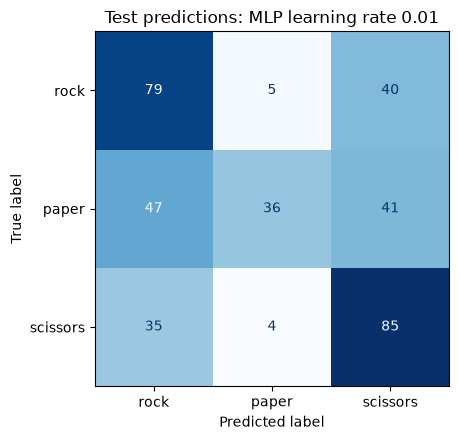

Misclassified test images: 172 out of 372


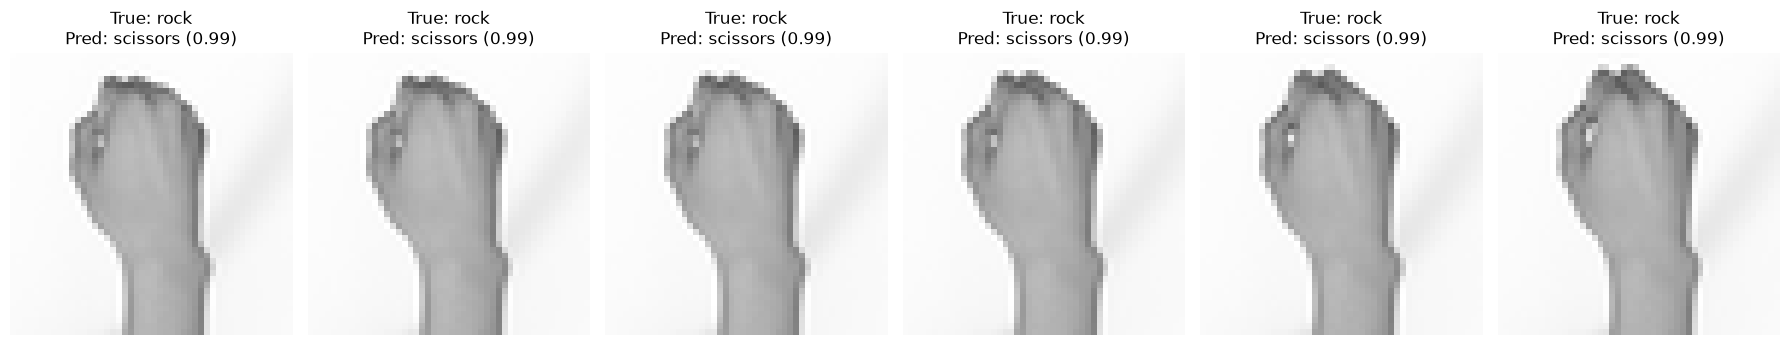

In [18]:
# Inspect the selected network's mistakes, rather than picking a model after seeing test scores.
final_predictions = chosen_network.predict(network_test)
final_probabilities = chosen_network.predict_proba(network_test)

print(classification_report(y_test, final_predictions, target_names=CLASSES, digits=3))
cm = confusion_matrix(y_test, final_predictions, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Test predictions: {chosen_network_name}")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=160)
plt.show()

incorrect = np.flatnonzero(final_predictions != y_test)
print(f"Misclassified test images: {len(incorrect)} out of {len(y_test)}")
if len(incorrect):
    show = incorrect[:min(6, len(incorrect))]
    fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3.4))
    for ax, i in zip(np.atleast_1d(axes), show):
        ax.imshow(images_test[i], cmap="gray", vmin=0, vmax=1)
        confidence = final_probabilities[i, final_predictions[i]]
        ax.set_title(f"True: {CLASSES[y_test[i]]}\nPred: {CLASSES[final_predictions[i]]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "misclassified_examples.png", dpi=160)
    plt.show()

## 10. What we found

We kept the original pixel model as a reference, then tested whether PCA and a small neural network changed the results. The comparison below uses the numbers from our experiments, including the separate test images. We chose the PCA component count and neural network settings from validation performance **before** looking at the final test scores.

The main things we wanted to understand were whether PCA could make the input smaller without hurting classification too much, whether a nonlinear network made a difference, and what kinds of mistakes remained.


In [19]:
from IPython.display import Markdown, display

# Read the results already calculated above. Nothing here retrains or retests a model.
def result_for(table, name):
    match = table.loc[table["model"] == name]
    if len(match) != 1:
        raise ValueError(f"Expected one result for {name!r}, found {len(match)}")
    return match.iloc[0]

raw_test = result_for(test_results, "Logistic regression (pixels)")
pca_name = f"Logistic regression (PCA {best_k})"
pca_test = result_for(test_results, pca_name)
network_test_result = result_for(test_results, chosen_network_name)
pca_validation = result_for(logistic_results, pca_name)
network_validation = result_for(network_results, chosen_network_name)

raw_features = int(X_train.shape[1])
reduction = 100 * (1 - best_k / raw_features)
retained_variance = 100 * float(np.sum(pca.explained_variance_ratio_[:best_k]))
raw_acc = float(raw_test["test_accuracy"])
pca_acc = float(pca_test["test_accuracy"])
net_acc = float(network_test_result["test_accuracy"])

# Compare measured accuracies without assuming the outcome in advance.
def compare_accuracy(first, second, first_name, second_name):
    gap = 100 * (first - second)
    if abs(gap) < 0.05:
        return f"{first_name} and {second_name} had essentially the same test accuracy."
    direction = "higher" if gap > 0 else "lower"
    return (f"{first_name} was {abs(gap):.1f} percentage points {direction} "
            f"than {second_name} on this test set.")

pca_comparison = compare_accuracy(pca_acc, raw_acc, "The PCA-based classifier", "the pixel baseline")
network_comparison = compare_accuracy(net_acc, pca_acc, "The neural network", "the PCA logistic regression model")

train_val_gap = 100 * (float(network_validation["training_accuracy"]) -
                       float(network_validation["validation_accuracy"]))
if train_val_gap > 5:
    gap_note = ("Its training accuracy was noticeably higher than its validation accuracy, "
                "so overfitting is worth considering.")
elif train_val_gap < -5:
    gap_note = ("Its validation accuracy was higher than its training accuracy in this run. "
                "That difference may depend on the split and training conditions.")
else:
    gap_note = ("Its training and validation accuracies were fairly close, although that "
                "alone does not prove the model will generalize to new situations.")

# Identify the most common specific confusion (excluding correct predictions).
wrong = cm.copy()
np.fill_diagonal(wrong, 0)
error_total = int(wrong.sum())
if error_total:
    true_idx, pred_idx = np.unravel_index(int(np.argmax(wrong)), wrong.shape)
    largest_confusion = int(wrong[true_idx, pred_idx])
    error_note = (f"The selected network made {error_total} incorrect predictions out of "
                  f"{len(y_test)} test images. Its most frequent error was predicting "
                  f"**{CLASSES[pred_idx]}** for **{CLASSES[true_idx]}** "
                  f"({largest_confusion} image(s)). We should look at those specific "
                  "images before deciding why they were difficult.")
else:
    error_note = (f"The selected network correctly classified all {len(y_test)} images "
                  "in this test collection. That is encouraging, but it doesn't tell us "
                  "how it would handle new users or backgrounds.")

first_limit = iteration_results.iloc[0]
last_limit = iteration_results.iloc[-1]
iteration_note = (
    f"For the logistic regression experiment with {iteration_k} PCA components, "
    f"training cross-entropy was {float(first_limit['training_loss']):.3f} "
    f"with a maximum of {int(first_limit['iteration_limit'])} iterations and "
    f"{float(last_limit['training_loss']):.3f} "
    f"with a maximum of {int(last_limit['iteration_limit'])}. "
    "These values come from separate fits with different limits, not a loss "
    "history from one continuous training run."
)

summary = f"""
### Results at a glance

| Model | Test accuracy | Balanced accuracy | Macro F1 | Cross-entropy |
|---|---:|---:|---:|---:|
| Logistic regression (pixels) | {raw_acc:.1%} | {float(raw_test['test_balanced_accuracy']):.1%} | {float(raw_test['test_macro_f1']):.3f} | {float(raw_test['test_log_loss']):.3f} |
| Logistic regression (PCA {best_k}) | {pca_acc:.1%} | {float(pca_test['test_balanced_accuracy']):.1%} | {float(pca_test['test_macro_f1']):.3f} | {float(pca_test['test_log_loss']):.3f} |
| {chosen_network_name} | {net_acc:.1%} | {float(network_test_result['test_balanced_accuracy']):.1%} | {float(network_test_result['test_macro_f1']):.3f} | {float(network_test_result['test_log_loss']):.3f} |

### What the comparisons show

We started with **{raw_features:,} grayscale pixel values** per image. The PCA setting chosen using validation results reduced that to **{best_k} components**, a **{reduction:.1f}% reduction** in the number of input features. Those components accounted for **{retained_variance:.1f}%** of the variation in the scaled training images. PCA captures variation in the images, not necessarily the features that best distinguish the gestures, so accuracy still matters.

On the **{len(y_test)} separately stored test images**, the pixel-based logistic regression model reached **{raw_acc:.1%} accuracy**, compared with **{pca_acc:.1%}** for logistic regression with PCA. {pca_comparison} The PCA classifier took **{float(pca_validation['training_seconds']):.2f} seconds** to fit, but PCA preprocessing itself took **{pca_seconds:.2f} seconds** in this run. That preprocessing cost needs to be considered when comparing training times.

The selected neural network was **{chosen_network_name}**, chosen from the validation experiments. It reached **{net_acc:.1%} test accuracy**, with a macro F1-score of **{float(network_test_result['test_macro_f1']):.3f}**. {network_comparison} {gap_note}

{iteration_note}

{error_note}

### What this does not tell us

These comparisons tell us how the models behaved on this dataset and with the settings we tried. They do not prove any model is universally optimal. The test images are stored separately, but exact-file checks cannot rule out closely related photos. We also have not established performance on different cameras, lighting conditions, backgrounds, or people. Testing those conditions would be a useful next step.
"""
display(Markdown(summary))



### Results at a glance

| Model | Test accuracy | Balanced accuracy | Macro F1 | Cross-entropy |
|---|---:|---:|---:|---:|
| Logistic regression (pixels) | 55.9% | 55.9% | 0.559 | 3.105 |
| Logistic regression (PCA 100) | 58.6% | 58.6% | 0.586 | 3.182 |
| MLP learning rate 0.01 | 53.8% | 53.8% | 0.522 | 3.241 |

### What the comparisons show

We started with **2,304 grayscale pixel values** per image. The PCA setting chosen using validation results reduced that to **100 components**, a **95.7% reduction** in the number of input features. Those components accounted for **95.1%** of the variation in the scaled training images. PCA captures variation in the images, not necessarily the features that best distinguish the gestures, so accuracy still matters.

On the **372 separately stored test images**, the pixel-based logistic regression model reached **55.9% accuracy**, compared with **58.6%** for logistic regression with PCA. The PCA-based classifier was 2.7 percentage points higher than the pixel baseline on this test set. The PCA classifier took **0.06 seconds** to fit, but PCA preprocessing itself took **1.51 seconds** in this run. That preprocessing cost needs to be considered when comparing training times.

The selected neural network was **MLP learning rate 0.01**, chosen from the validation experiments. It reached **53.8% test accuracy**, with a macro F1-score of **0.522**. The neural network was 4.8 percentage points lower than the PCA logistic regression model on this test set. Its training and validation accuracies were fairly close, although that alone does not prove the model will generalize to new situations.

For the logistic regression experiment with 50 PCA components, training cross-entropy was 0.121 with a maximum of 5 iterations and 0.046 with a maximum of 500. These values come from separate fits with different limits, not a loss history from one continuous training run.

The selected network made 172 incorrect predictions out of 372 test images. Its most frequent error was predicting **rock** for **paper** (47 image(s)). We should look at those specific images before deciding why they were difficult.

### What this does not tell us

These comparisons tell us how the models behaved on this dataset and with the settings we tried. They do not prove any model is universally optimal. The test images are stored separately, but exact-file checks cannot rule out closely related photos. We also have not established performance on different cameras, lighting conditions, backgrounds, or people. Testing those conditions would be a useful next step.


### Sources and reproducibility

- **Course:** ENGR 418, Applied Machine Learning for Engineers, UBC Okanagan.
- **Images:** `Dataset/rps` and `Dataset/rps-test-set` (we still need to record the original download link, dataset license, and whether the test images are related to the training images).
- **Reference:** The separately retained `principal-component-analysis-visualization.ipynb` is based on [DrGFreeman’s PCA visualization notebook](https://www.kaggle.com/code/drgfreeman/principal-component-analysis-visualization). This project notebook contains our comparisons.
- **Tools:** Python, NumPy, pandas, Pillow, Matplotlib, and scikit-learn.

The random seed is `42`, and the split is recorded in `results/data_split.csv`. The comparison tables and figures are saved in `results/`. Results may vary if we change the dataset, preprocessing, model settings, or software environment. The generated discussion above updates automatically when the notebook is run again.
